<a href="https://colab.research.google.com/github/aji405/Machine-learning-/blob/main/exp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Specific Boundary (S): ('Sunny', 'Warm', '?', 'Strong', '?', '?')

General Boundary (G):
('?', 'Warm', '?', '?', '?', '?')
('Sunny', '?', '?', '?', '?', '?')


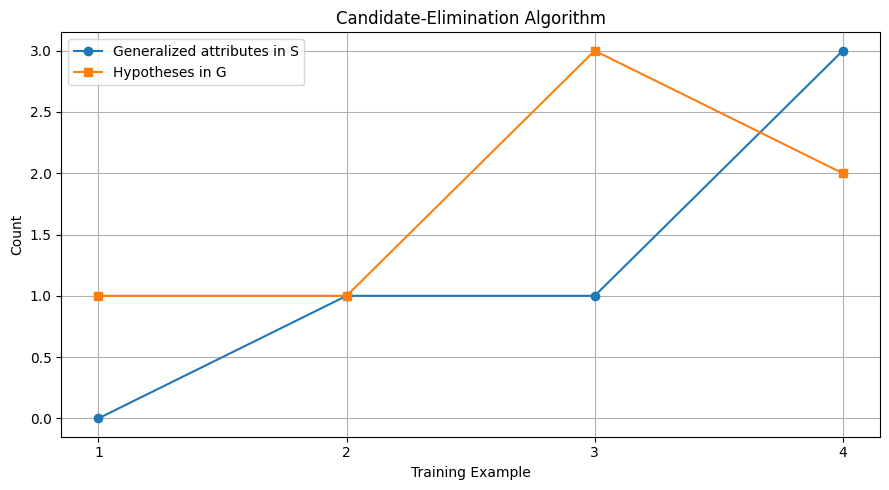

In [1]:
import csv
import matplotlib.pyplot as plt

# Create CSV file
data = [
    ["Sky", "AirTemp", "Humidity", "Wind", "Water", "Forecast", "EnjoySport"],
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same", "Yes"],
    ["Sunny", "Warm", "High", "Strong", "Warm", "Same", "Yes"],
    ["Rainy", "Cold", "High", "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High", "Strong", "Cool", "Change", "Yes"]
]

with open("training.csv", "w", newline="") as f:
    csv.writer(f).writerows(data)

with open("training.csv", "r") as f:
    rows = list(csv.reader(f))

examples = rows[1:]
attributes = rows[0][:-1]
n = len(attributes)
domains = [set(row[i] for row in examples) for i in range(n)]

S = tuple("Ø" for _ in range(n))
G = [tuple("?" for _ in range(n))]

def covers(h, x):
    return all(a == "?" or a == b for a, b in zip(h, x))

def more_general(h1, h2):
    return all(a == "?" or a == b or b == "Ø"
               for a, b in zip(h1, h2))

def generalize(h, x):
    return tuple(x[i] if h[i] == "Ø" else
                 h[i] if h[i] == x[i] or h[i] == "?" else "?"
                 for i in range(n))

def specialize(h, x):
    result = []
    for i in range(n):
        if h[i] == "?":
            for value in domains[i]:
                if value != x[i]:
                    new_h = list(h)
                    new_h[i] = value
                    candidate = tuple(new_h)
                    if more_general(candidate, S):
                        result.append(candidate)
    return result

history = []

for row in examples:
    x, target = row[:-1], row[-1]

    if target == "Yes":
        G = [g for g in G if covers(g, x)]
        if not covers(S, x):
            S = generalize(S, x)
        G = [g for g in G if more_general(g, S)]

    else:
        new_G = []
        for g in G:
            if covers(g, x):
                new_G.extend(specialize(g, x))
            else:
                new_G.append(g)

        G = list(set(new_G))
        G = [g for g in G if more_general(g, S)]

    history.append((S, G.copy()))

print("Specific Boundary (S):", S)
print("\nGeneral Boundary (G):")
for g in G:
    print(g)

# Plot boundary progress
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(history) + 1),
         [sum(v == "?" for v in s) for s, g in history],
         marker="o", label="Generalized attributes in S")
plt.plot(range(1, len(history) + 1),
         [len(g) for s, g in history],
         marker="s", label="Hypotheses in G")

plt.xlabel("Training Example")
plt.ylabel("Count")
plt.title("Candidate-Elimination Algorithm")
plt.xticks(range(1, len(history) + 1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
